# Swin-Tiny from Scratch — Crack / No-Crack Classification

This notebook trains **Swin-Tiny from scratch** for binary crack classification.

### Main settings
- Image size: 224 × 224
- Model: `swin_tiny_patch4_window7_224`
- **Pretrained = False**
- Epochs: **50**
- Optimizer: AdamW
- Maximum learning rate: `1e-4`
- Warm-up + cosine decay
- Gradient clipping
- Early stopping
- Best model checkpoint
- Training/validation curves
- Test accuracy, classification report and confusion matrix

## 1. Install required packages

Run this cell once if the packages are not already installed.

> If you are using Anaconda/Jupyter and PyTorch is already installed, you can skip the installation cell.

In [1]:
# Run only if needed.
# Uncomment the next line if timm is not installed.

# %pip install torch torchvision timm scikit-learn pandas matplotlib seaborn pillow

## 2. Imports

In [15]:
import os
import time
import copy
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("PyTorch version :", torch.__version__)
print("timm version    :", timm.__version__)

PyTorch version : 2.11.0+cu130
timm version    : 1.0.29


## 3. Configuration

### Important
Change only `DATA_ROOT` if your dataset is stored somewhere else.

Expected folder structure:

```text
dataset/
├── train/
│   ├── crack/
│   └── no_crack/
├── val/
│   ├── crack/
│   └── no_crack/
└── test/
    ├── crack/
    └── no_crack/
```

In [16]:
# ============================================================
# PATHS
# ============================================================

DATA_ROOT = Path(
    r"C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset"
)

OUTPUT_DIR = Path(
    r"C:\Users\Students\Desktop\Crack classification(Indhu)\Output"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "logs"
PLOT_DIR = OUTPUT_DIR / "plots"
REPORT_DIR = OUTPUT_DIR / "reports"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# DATA / TRAINING SETTINGS
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0

# Your requested training duration
EPOCHS = 50

# Stable learning rate
LR = 1e-4
MIN_LR = 1e-6

WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 5

NUM_CLASSES = 2

SEED = 42
GRAD_CLIP_NORM = 1.0

# Training will stop if validation accuracy does not improve
# for this many consecutive epochs.
PATIENCE = 7

MODEL_KEY = "swin_tiny_scratch"
TIMM_NAME = "swin_tiny_patch4_window7_224"

# VERY IMPORTANT:
# The model is created with random initialization.
PRETRAINED = False

print("Configuration loaded.")
print("Epochs       :", EPOCHS)
print("Batch size   :", BATCH_SIZE)
print("Learning rate:", LR)
print("Pretrained   :", PRETRAINED)

Configuration loaded.
Epochs       : 50
Batch size   : 32
Learning rate: 0.0001
Pretrained   : False


## 4. Reproducibility and device

In [17]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: CUDA GPU is not available. Training on CPU will be much slower.")

Device: cuda
GPU: NVIDIA GeForce RTX 5070


## 5. Check dataset

In [18]:
# ============================================================
# DATASET DIRECTORIES
# ============================================================

TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR   = DATA_ROOT / "val"
TEST_DIR  = DATA_ROOT / "test"

print("Train:", TRAIN_DIR)
print("Val  :", VAL_DIR)
print("Test :", TEST_DIR)

assert TRAIN_DIR.exists(), f"Train folder not found: {TRAIN_DIR}"
assert VAL_DIR.exists(), f"Validation folder not found: {VAL_DIR}"
assert TEST_DIR.exists(), f"Test folder not found: {TEST_DIR}"

print("\nDataset folders found successfully.")

Train: C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset\train
Val  : C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset\val
Test : C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset\test

Dataset folders found successfully.


## 6. Image transforms

Training images use augmentation. Validation and test images use only resizing and normalization.

In [19]:
# ============================================================
# TRANSFORMS
# ============================================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Transforms created.")

Transforms created.


## 7. Create ImageFolder datasets

In [20]:
# ============================================================
# DATASETS
# ============================================================

train_ds = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

print("Class mapping:", train_ds.class_to_idx)
print("Train images:", len(train_ds))
print("Val images  :", len(val_ds))
print("Test images :", len(test_ds))

# Check that all splits use the same class mapping.
assert train_ds.class_to_idx == val_ds.class_to_idx,     "Train and validation class mappings are different."

assert train_ds.class_to_idx == test_ds.class_to_idx,     "Train and test class mappings are different."

assert NUM_CLASSES == len(train_ds.classes),     f"Expected {NUM_CLASSES} classes, found {len(train_ds.classes)}."

print("\nClasses:", train_ds.classes)

Class mapping: {'crack': 0, 'no_crack': 1}
Train images: 28000
Val images  : 8000
Test images : 4000

Classes: ['crack', 'no_crack']


## 8. Check class distribution

This is useful before training so we can see whether the dataset is balanced.

In [21]:
# ============================================================
# CLASS DISTRIBUTION
# ============================================================

def get_class_counts(dataset):
    targets = np.array(dataset.targets)
    counts = np.bincount(targets, minlength=len(dataset.classes))
    return {
        dataset.classes[i]: int(counts[i])
        for i in range(len(dataset.classes))
    }

train_counts = get_class_counts(train_ds)
val_counts = get_class_counts(val_ds)
test_counts = get_class_counts(test_ds)

print("Train:", train_counts)
print("Val  :", val_counts)
print("Test :", test_counts)

distribution_df = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    **{
        class_name: [
            train_counts[class_name],
            val_counts[class_name],
            test_counts[class_name]
        ]
        for class_name in train_ds.classes
    }
})

display(distribution_df)

Train: {'crack': 14000, 'no_crack': 14000}
Val  : {'crack': 4000, 'no_crack': 4000}
Test : {'crack': 2000, 'no_crack': 2000}


,Split,crack,no_crack
0,Train,14000,14000
1,Validation,4000,4000
2,Test,2000,2000


## 9. DataLoaders

In [22]:
# ============================================================
# DATALOADERS
# ============================================================

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches: 875
Val batches  : 250
Test batches : 125


## 10. Display a few training images

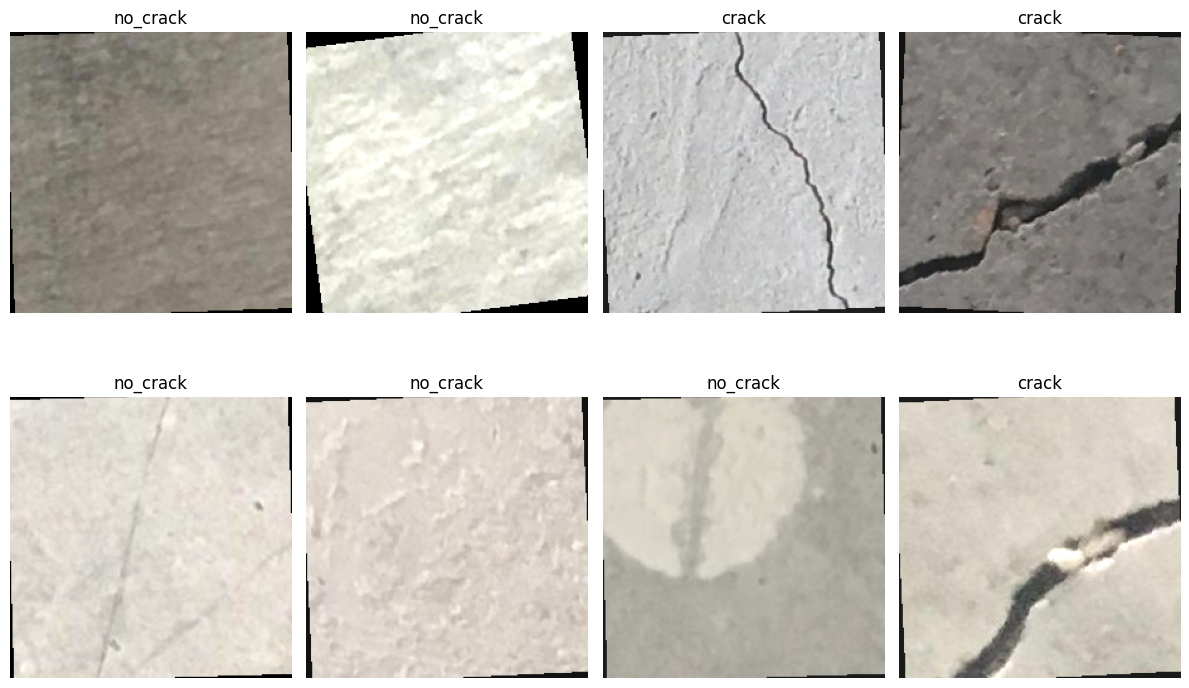

In [10]:
# ============================================================
# SAMPLE IMAGES
# ============================================================

def denormalize(img):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = img.cpu() * std + mean
    return torch.clamp(img, 0, 1)

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    img = denormalize(images[i]).permute(1, 2, 0).numpy()
    plt.imshow(img)
    plt.title(train_ds.classes[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 11. Build Swin-Tiny **from scratch**

This is the key requirement.

`pretrained=False` means the model does **not** load ImageNet pretrained weights. Its weights are initialized randomly and learned using your crack dataset.

In [11]:
# ============================================================
# SWIN-TINY FROM SCRATCH
# ============================================================

model = timm.create_model(
    TIMM_NAME,
    pretrained=False,
    num_classes=NUM_CLASSES
)

model = model.to(DEVICE)

print("Model created.")
print("Pretrained:", PRETRAINED)

Model created.
Pretrained: False


## 12. Verify model output and parameter count

In [12]:
# ============================================================
# FORWARD-PASS CHECK
# ============================================================

dummy = torch.randn(
    2,
    3,
    IMG_SIZE,
    IMG_SIZE,
    device=DEVICE
)

model.eval()

with torch.no_grad():
    dummy_out = model(dummy)

model.train()

print("Output shape:", tuple(dummy_out.shape))

if tuple(dummy_out.shape) != (2, NUM_CLASSES):
    raise RuntimeError(
        f"Unexpected output shape: {tuple(dummy_out.shape)}"
    )

if not torch.isfinite(dummy_out).all():
    raise RuntimeError(
        "Model produced NaN/Inf in initial forward pass."
    )

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Initial forward pass: OK")

Output shape: (2, 2)
Total parameters    : 27,520,892
Trainable parameters: 27,520,892
Initial forward pass: OK


## 13. Loss function and optimizer

We use Cross Entropy Loss for the two-class classification task and AdamW for optimization.

In [13]:
# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

print("Loss:", criterion)
print("Optimizer: AdamW")
print("Initial LR:", LR)
print("Weight decay:", WEIGHT_DECAY)

Loss: CrossEntropyLoss()
Optimizer: AdamW
Initial LR: 0.0001
Weight decay: 0.0001


## 14. Warm-up + cosine learning-rate scheduler

The learning rate starts near `1e-6`, warms up toward `1e-4`, and then gradually decreases.

This avoids the unstable jump to `5e-4` from the earlier run.

In [14]:
# ============================================================
# WARM-UP + COSINE DECAY
# ============================================================

def lr_lambda(epoch):
    # --------------------------------------------------------
    # WARM-UP
    # --------------------------------------------------------
    if epoch < WARMUP_EPOCHS:
        start_lr = MIN_LR
        target_lr = LR

        progress = epoch / WARMUP_EPOCHS

        current_lr = (
            start_lr
            + (target_lr - start_lr) * progress
        )

        return current_lr / LR

    # --------------------------------------------------------
    # COSINE DECAY
    # --------------------------------------------------------
    progress = (
        epoch - WARMUP_EPOCHS
    ) / max(
        1,
        EPOCHS - WARMUP_EPOCHS
    )

    cosine_factor = 0.5 * (
        1 + np.cos(np.pi * progress)
    )

    return (
        MIN_LR / LR
        + (1 - MIN_LR / LR) * cosine_factor
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lr_lambda
)

print("Scheduler: Warm-up + Cosine Decay")
print("Maximum LR:", LR)
print("Minimum LR:", MIN_LR)
print("Warm-up epochs:", WARMUP_EPOCHS)

Scheduler: Warm-up + Cosine Decay
Maximum LR: 0.0001
Minimum LR: 1e-06
Warm-up epochs: 5


## 15. Training function

In [15]:
# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        if not torch.isfinite(outputs).all():
            raise RuntimeError(
                "NaN/Inf detected in model output."
            )

        loss = criterion(
            outputs,
            labels
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                "NaN/Inf detected in training loss."
            )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP_NORM
        )

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

## 16. Validation function

In [16]:
# ============================================================
# VALIDATION
# ============================================================

@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

## 17. Start a completely new training run

Do **not** load the old unstable checkpoint. This notebook starts the Swin-Tiny model from random initialization.

In [17]:
# ============================================================
# TRAINING SETUP
# ============================================================

RESUME_TRAINING = False

resume_path = CHECKPOINT_DIR / f"{MODEL_KEY}_resume.pt"
best_path = CHECKPOINT_DIR / f"{MODEL_KEY}_best.pt"
csv_log_path = LOG_DIR / f"{MODEL_KEY}_epoch_log.csv"
history_path = LOG_DIR / f"{MODEL_KEY}_history.json"

print("=" * 70)
print("STARTING A NEW SWIN-TINY TRAINING RUN")
print("=" * 70)
print("Model          :", MODEL_KEY)
print("Architecture   :", TIMM_NAME)
print("Pretrained     :", PRETRAINED)
print("Epochs         :", EPOCHS)
print("Batch size     :", BATCH_SIZE)
print("Maximum LR     :", LR)
print("Minimum LR     :", MIN_LR)
print("Warm-up epochs :", WARMUP_EPOCHS)
print("Weight decay   :", WEIGHT_DECAY)
print("Gradient clip  :", GRAD_CLIP_NORM)
print("=" * 70)

STARTING A NEW SWIN-TINY TRAINING RUN
Model          : swin_tiny_scratch
Architecture   : swin_tiny_patch4_window7_224
Pretrained     : False
Epochs         : 50
Batch size     : 32
Maximum LR     : 0.0001
Minimum LR     : 1e-06
Warm-up epochs : 5
Weight decay   : 0.0001
Gradient clip  : 1.0


## 18. Train the model

The notebook:
1. Trains for up to 50 epochs.
2. Saves the best validation model.
3. Logs every epoch.
4. Uses early stopping if validation accuracy stops improving.

In [18]:
# ============================================================
# SWIN-TINY TRAINING
# AMP + SAFE RESUME + CHECKPOINTING
# ============================================================

from tqdm.auto import tqdm
import copy
import time
import json
import pandas as pd
import torch


# ============================================================
# ENABLE CUDA PERFORMANCE OPTIMIZATIONS
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    print("CUDA:", torch.version.cuda)
    print("GPU :", torch.cuda.get_device_name(0))


# ============================================================
# MIXED PRECISION
# ============================================================

USE_AMP = True

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("AMP enabled:", USE_AMP)


# ============================================================
# INITIAL VALUES
# ============================================================

start_epoch = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": []
}

best_val_acc = -1.0

best_state = copy.deepcopy(
    model.state_dict()
)

epochs_no_improve = 0

stopped_early = False


# ============================================================
# RESUME FROM EPOCH 1 CHECKPOINT
# ============================================================

if not resume_path.exists():

    raise FileNotFoundError(
        f"\nCheckpoint not found:\n{resume_path}\n\n"
        "Your Epoch 1 checkpoint is required."
    )


print("=" * 80)
print("LOADING COMPLETED EPOCH 1")
print("=" * 80)


checkpoint = torch.load(
    resume_path,
    map_location=DEVICE
)


required_keys = [
    "epoch",
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "best_val_acc",
    "history"
]


missing_keys = [
    key
    for key in required_keys
    if key not in checkpoint
]


if missing_keys:

    raise RuntimeError(
        "Checkpoint is missing required keys:\n"
        f"{missing_keys}"
    )


# ============================================================
# LOAD MODEL
# ============================================================

model.load_state_dict(
    checkpoint["model_state_dict"]
)


# ============================================================
# LOAD OPTIMIZER
# ============================================================

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)


# ============================================================
# LOAD SCHEDULER
# ============================================================

scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)


# ============================================================
# LOAD TRAINING STATE
# ============================================================

start_epoch = checkpoint["epoch"]

best_val_acc = checkpoint[
    "best_val_acc"
]

history = checkpoint[
    "history"
]

epochs_no_improve = checkpoint.get(
    "epochs_no_improve",
    0
)


# ============================================================
# LOAD BEST MODEL
# ============================================================

if "best_state" in checkpoint:

    best_state = checkpoint[
        "best_state"
    ]

elif best_path.exists():

    best_state = torch.load(
        best_path,
        map_location=DEVICE
    )

else:

    best_state = copy.deepcopy(
        model.state_dict()
    )


print(
    f"Checkpoint epoch: {start_epoch}"
)

print(
    f"Best validation accuracy: "
    f"{best_val_acc * 100:.2f}%"
)


# ============================================================
# IMPORTANT:
# YOUR OLD CHECKPOINT WAS SAVED BEFORE scheduler.step()
#
# Therefore Epoch 1 checkpoint still contains the Epoch 1 LR.
# Advance scheduler ONCE so Epoch 2 starts with the correct LR.
# ============================================================

if start_epoch == 1:

    scheduler.step()

    print(
        "Scheduler advanced to Epoch 2."
    )


# ============================================================
# START TIMER
# ============================================================

start_time = time.time()


# ============================================================
# TRAINING INFORMATION
# ============================================================

print()
print("=" * 80)
print("SWIN-TINY TRAINING WITH AMP")
print("=" * 80)

print(
    f"Device         : {DEVICE}"
)

print(
    f"GPU            : "
    f"{torch.cuda.get_device_name(0)}"
)

print(
    f"Epochs         : {EPOCHS}"
)

print(
    f"Starting epoch : {start_epoch + 1}"
)

print(
    f"Batch size     : {BATCH_SIZE}"
)

print(
    f"Train batches  : {len(train_loader)}"
)

print(
    f"Val batches    : {len(val_loader)}"
)

print(
    f"AMP            : {USE_AMP}"
)

print(
    f"Current LR     : "
    f"{optimizer.param_groups[0]['lr']:.6g}"
)

print("=" * 80)


# ============================================================
# EPOCH LOOP
# ============================================================

for epoch in range(
    start_epoch,
    EPOCHS
):

    epoch_start_time = time.time()

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # EPOCH HEADER
    # ========================================================

    print()
    print("=" * 80)

    print(
        f"EPOCH {epoch + 1}/{EPOCHS}"
    )

    print("=" * 80)

    print(
        f"Learning Rate: {current_lr:.6g}"
    )


    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0


    train_bar = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch + 1}/{EPOCHS}",
        unit="batch"
    )


    for batch_idx, (
        images,
        labels
    ) in enumerate(train_bar):


        # ----------------------------------------------------
        # MOVE DATA TO GPU
        # ----------------------------------------------------

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )


        # ----------------------------------------------------
        # CLEAR GRADIENTS
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # MIXED PRECISION FORWARD PASS
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            outputs = model(
                images
            )

            if not torch.isfinite(
                outputs
            ).all():

                raise RuntimeError(
                    f"NaN/Inf detected in model "
                    f"output at epoch "
                    f"{epoch + 1}, "
                    f"batch {batch_idx + 1}"
                )

            loss = criterion(
                outputs,
                labels
            )


        # ----------------------------------------------------
        # CHECK LOSS
        # ----------------------------------------------------

        if not torch.isfinite(loss):

            raise RuntimeError(
                f"NaN/Inf detected in loss "
                f"at epoch "
                f"{epoch + 1}, "
                f"batch {batch_idx + 1}"
            )


        # ----------------------------------------------------
        # SCALED BACKWARD PASS
        # ----------------------------------------------------

        scaler.scale(
            loss
        ).backward()


        # ----------------------------------------------------
        # UNSCALE BEFORE GRADIENT CLIPPING
        # ----------------------------------------------------

        scaler.unscale_(
            optimizer
        )


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP_NORM
        )


        # ----------------------------------------------------
        # OPTIMIZER STEP
        # ----------------------------------------------------

        scaler.step(
            optimizer
        )

        scaler.update()


        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        batch_size_actual = labels.size(0)

        running_loss += (
            loss.item()
            * batch_size_actual
        )

        predictions = outputs.argmax(
            dim=1
        )

        running_correct += (
            predictions == labels
        ).sum().item()

        running_total += (
            batch_size_actual
        )


        running_loss_avg = (
            running_loss /
            running_total
        )

        running_acc = (
            running_correct /
            running_total
        )


        train_bar.set_postfix({

            "loss":
                f"{running_loss_avg:.4f}",

            "acc":
                f"{running_acc * 100:.2f}%"

        })


    # ========================================================
    # TRAINING RESULTS
    # ========================================================

    train_loss = (
        running_loss /
        running_total
    )

    train_acc = (
        running_correct /
        running_total
    )


    print()
    print(
        f"TRAIN COMPLETE | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc * 100:.2f}%"
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_running_loss = 0.0
    val_running_correct = 0
    val_running_total = 0


    val_bar = tqdm(
        val_loader,
        desc=f"Validation Epoch {epoch + 1}/{EPOCHS}",
        unit="batch"
    )


    with torch.no_grad():

        for images, labels in val_bar:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            # ------------------------------------------------
            # AMP VALIDATION
            # ------------------------------------------------

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                outputs = model(
                    images
                )

                loss = criterion(
                    outputs,
                    labels
                )


            batch_size_actual = labels.size(0)

            val_running_loss += (
                loss.item()
                * batch_size_actual
            )

            predictions = outputs.argmax(
                dim=1
            )

            val_running_correct += (
                predictions == labels
            ).sum().item()

            val_running_total += (
                batch_size_actual
            )


            val_running_loss_avg = (
                val_running_loss /
                val_running_total
            )

            val_running_acc = (
                val_running_correct /
                val_running_total
            )


            val_bar.set_postfix({

                "loss":
                    f"{val_running_loss_avg:.4f}",

                "acc":
                    f"{val_running_acc * 100:.2f}%"

            })


    # ========================================================
    # VALIDATION RESULTS
    # ========================================================

    val_loss = (
        val_running_loss /
        val_running_total
    )

    val_acc = (
        val_running_correct /
        val_running_total
    )


    # ========================================================
    # UPDATE HISTORY
    # ========================================================

    history["train_loss"].append(
        train_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_acc"].append(
        val_acc
    )

    history["learning_rate"].append(
        current_lr
    )


    # ========================================================
    # BEST MODEL
    # ========================================================

    marker = ""


    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_no_improve = 0

        marker = " ⭐ BEST MODEL"


        torch.save(
            best_state,
            best_path
        )


    else:

        epochs_no_improve += 1


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = (
        time.time()
        - epoch_start_time
    )


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    print()
    print("-" * 80)

    print(
        f"EPOCH {epoch + 1}/{EPOCHS} COMPLETED"
    )

    print("-" * 80)

    print(
        f"Train Loss     : "
        f"{train_loss:.4f}"
    )

    print(
        f"Train Accuracy : "
        f"{train_acc * 100:.2f}%"
    )

    print(
        f"Val Loss       : "
        f"{val_loss:.4f}"
    )

    print(
        f"Val Accuracy   : "
        f"{val_acc * 100:.2f}%"
    )

    print(
        f"Learning Rate  : "
        f"{current_lr:.6g}"
    )

    print(
        f"Epoch Time     : "
        f"{epoch_time / 60:.2f} minutes"
    )

    print(
        f"Best Val Acc   : "
        f"{best_val_acc * 100:.2f}%"
        f"{marker}"
    )

    print(
        f"No Improvement : "
        f"{epochs_no_improve}/{PATIENCE}"
    )

    print("-" * 80)


    # ========================================================
    # CSV LOG
    # ========================================================

    pd.DataFrame([{

        "epoch":
            epoch + 1,

        "train_loss":
            train_loss,

        "train_acc":
            train_acc,

        "val_loss":
            val_loss,

        "val_acc":
            val_acc,

        "learning_rate":
            current_lr

    }]).to_csv(

        csv_log_path,

        mode="a",

        header=not csv_log_path.exists(),

        index=False
    )


    # ========================================================
    # STEP SCHEDULER
    # ========================================================
    #
    # IMPORTANT:
    # Step BEFORE saving checkpoint.
    #
    # This means the checkpoint always contains the LR
    # required for the NEXT epoch.
    # ========================================================

    scheduler.step()


    # ========================================================
    # SAVE RESUME CHECKPOINT
    # ========================================================

    torch.save({

        "epoch":
            epoch + 1,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "best_val_acc":
            best_val_acc,

        "best_state":
            best_state,

        "epochs_no_improve":
            epochs_no_improve,

        "history":
            history

    }, resume_path)


    print(
        f"Checkpoint saved:\n"
        f"{resume_path}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_no_improve >= PATIENCE:

        print()
        print("=" * 80)

        print(
            "EARLY STOPPING"
        )

        print(
            f"No validation improvement "
            f"for {PATIENCE} epochs."
        )

        print("=" * 80)

        stopped_early = True

        break


# ============================================================
# LOAD BEST MODEL
# ============================================================

model.load_state_dict(
    best_state
)


# ============================================================
# SAVE BEST MODEL
# ============================================================

torch.save(
    best_state,
    best_path
)


# ============================================================
# SAVE HISTORY
# ============================================================

with open(
    history_path,
    "w"
) as f:

    json.dump(
        history,
        f,
        indent=2
    )


# ============================================================
# FINAL TIME
# ============================================================

training_time = (
    time.time()
    - start_time
)


status = (
    "Stopped early"
    if stopped_early
    else "Completed all epochs"
)


print()
print("=" * 80)
print("TRAINING FINISHED")
print("=" * 80)

print(
    "Status:",
    status
)

print(
    f"Best validation accuracy: "
    f"{best_val_acc * 100:.2f}%"
)

print(
    f"Total training time: "
    f"{training_time / 60:.2f} minutes"
)

print(
    f"Best model:\n{best_path}"
)

print(
    f"Resume checkpoint:\n{resume_path}"
)

print(
    f"Training log:\n{csv_log_path}"
)

print("=" * 80)

CUDA: 13.0
GPU : NVIDIA GeForce RTX 5070
AMP enabled: True
LOADING COMPLETED EPOCH 1


C:\Users\Students\AppData\Local\Temp\ipykernel_22260\4204831667.py:204: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Checkpoint epoch: 1
Best validation accuracy: 85.41%
Scheduler advanced to Epoch 2.

SWIN-TINY TRAINING WITH AMP
Device         : cuda
GPU            : NVIDIA GeForce RTX 5070
Epochs         : 50
Starting epoch : 2
Batch size     : 32
Train batches  : 875
Val batches    : 250
AMP            : True
Current LR     : 2.08e-05

EPOCH 2/50
Learning Rate: 2.08e-05


Training Epoch 2/50: 100%|██████████| 875/875 [03:03<00:00,  4.78batch/s, loss=0.3003, acc=87.71%]



TRAIN COMPLETE | Loss: 0.3003 | Accuracy: 87.71%


Validation Epoch 2/50: 100%|██████████| 250/250 [00:23<00:00, 10.72batch/s, loss=0.2085, acc=90.38%]


... (189 outputs left out)

Training Epoch 50/50: 100%|██████████| 875/875 [02:46<00:00,  5.25batch/s, loss=0.0862, acc=96.89%]



TRAIN COMPLETE | Loss: 0.0862 | Accuracy: 96.89%


Validation Epoch 50/50: 100%|██████████| 250/250 [00:19<00:00, 12.50batch/s, loss=0.0975, acc=96.69%]



--------------------------------------------------------------------------------
EPOCH 50/50 COMPLETED
--------------------------------------------------------------------------------
Train Loss     : 0.0862
Train Accuracy : 96.89%
Val Loss       : 0.0975
Val Accuracy   : 96.69%
Learning Rate  : 1.12058e-06
Epoch Time     : 3.11 minutes
Best Val Acc   : 96.70%
No Improvement : 1/7
--------------------------------------------------------------------------------
Checkpoint saved:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\checkpoints\swin_tiny_scratch_resume.pt

TRAINING FINISHED
Status: Completed all epochs
Best validation accuracy: 96.70%
Total training time: 154.54 minutes
Best model:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\checkpoints\swin_tiny_scratch_best.pt
Resume checkpoint:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\checkpoints\swin_tiny_scratch_resume.pt
Training log:
C:\Users\Students\Desktop\Crack classification(Indhu)

In [19]:
print("Train workers:", train_loader.num_workers)
print("Val workers:", val_loader.num_workers)

print("Train pin_memory:", train_loader.pin_memory)
print("Val pin_memory:", val_loader.pin_memory)

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train workers: 0
Val workers: 0
Train pin_memory: True
Val pin_memory: True
Batch size: 32
Train batches: 875
Val batches: 250


In [20]:
!nvidia-smi

Mon Sep 28 19:30:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 616.56                 KMD Version: 616.56        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070      WDDM  |   00000000:01:00.0  On |                  N/A |
| 35%   48C    P1             25W /  250W |    3986MiB /  12227MiB |      3%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 19. Plot training loss and validation loss

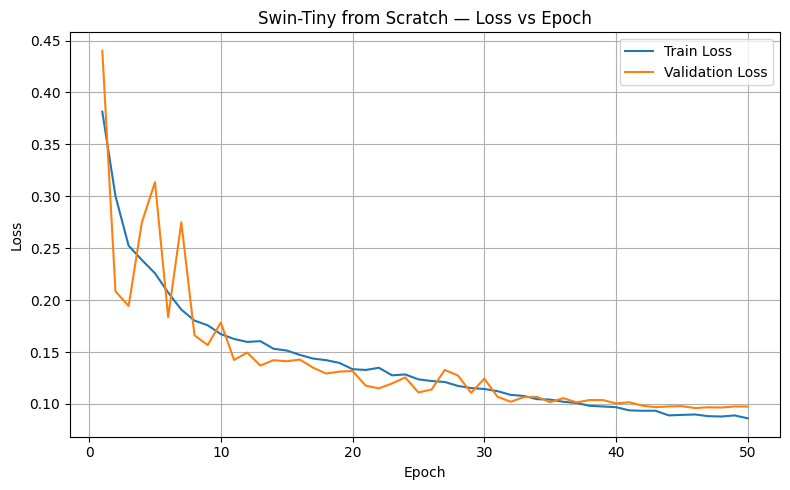

Saved: C:\Users\Students\Desktop\Crack classification(Indhu)\Output\plots\swin_tiny_scratch_loss_curve.png


In [21]:
# ============================================================
# LOSS CURVE
# ============================================================

epochs_done = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_done,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_done,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Swin-Tiny from Scratch — Loss vs Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()

loss_plot_path = PLOT_DIR / f"{MODEL_KEY}_loss_curve.png"
plt.savefig(loss_plot_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", loss_plot_path)

## 20. Plot training and validation accuracy

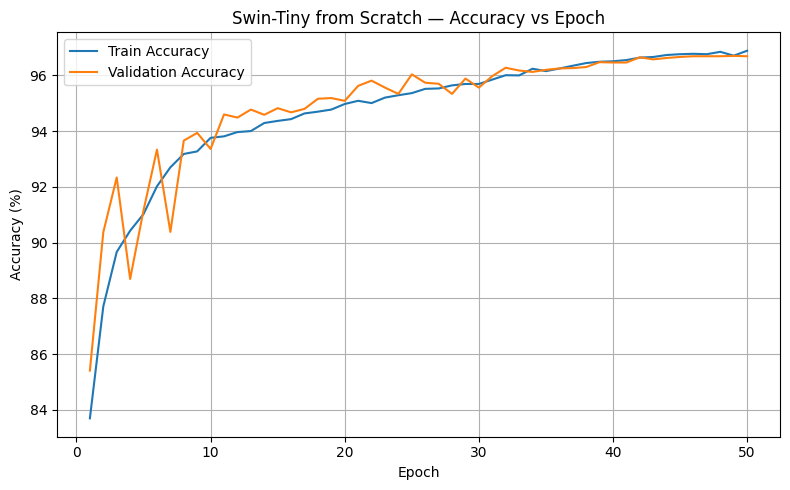

Saved: C:\Users\Students\Desktop\Crack classification(Indhu)\Output\plots\swin_tiny_scratch_accuracy_curve.png


In [22]:
# ============================================================
# ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_done,
    np.array(history["train_acc"]) * 100,
    label="Train Accuracy"
)

plt.plot(
    epochs_done,
    np.array(history["val_acc"]) * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Swin-Tiny from Scratch — Accuracy vs Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()

acc_plot_path = PLOT_DIR / f"{MODEL_KEY}_accuracy_curve.png"
plt.savefig(acc_plot_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", acc_plot_path)

## 21. Plot learning-rate schedule

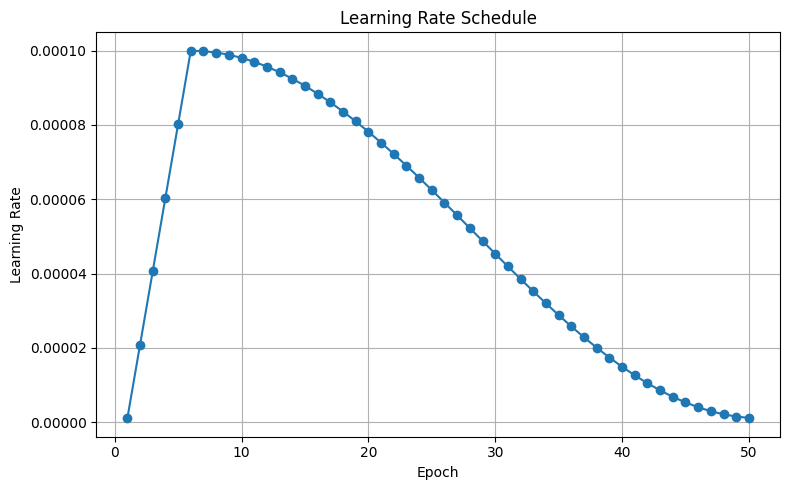

Saved: C:\Users\Students\Desktop\Crack classification(Indhu)\Output\plots\swin_tiny_scratch_learning_rate.png


In [23]:
# ============================================================
# LEARNING RATE CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_done,
    history["learning_rate"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.grid(True)

plt.tight_layout()

lr_plot_path = PLOT_DIR / f"{MODEL_KEY}_learning_rate.png"
plt.savefig(lr_plot_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", lr_plot_path)

## 22. Final test evaluation

The **test set is used only after training is finished**. The best validation checkpoint is evaluated here.

In [24]:
# ============================================================
# TEST PREDICTIONS
# ============================================================

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(dim=1)

        all_labels.extend(
            labels.numpy().tolist()
        )

        all_predictions.extend(
            predictions.cpu().numpy().tolist()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )


all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 60)
print("TEST RESULTS")
print("=" * 60)
print(f"Accuracy          : {test_accuracy * 100:.2f}%")
print(f"Weighted Precision: {precision * 100:.2f}%")
print(f"Weighted Recall   : {recall * 100:.2f}%")
print(f"Weighted F1       : {f1 * 100:.2f}%")
print("=" * 60)

TEST RESULTS
Accuracy          : 97.02%
Weighted Precision: 97.06%
Weighted Recall   : 97.02%
Weighted F1       : 97.02%


In [24]:
from sklearn.metrics import roc_auc_score

crack_probs = all_probabilities[:, 0]

y_true_crack = (all_labels == 0).astype(int)

roc_auc = roc_auc_score(
    y_true_crack,
    crack_probs
)

print(f"Swin-Tiny ROC-AUC: {roc_auc:.4f}")
print(f"Swin-Tiny ROC-AUC: {roc_auc * 100:.2f}%")

Swin-Tiny ROC-AUC: 0.9951
Swin-Tiny ROC-AUC: 99.51%


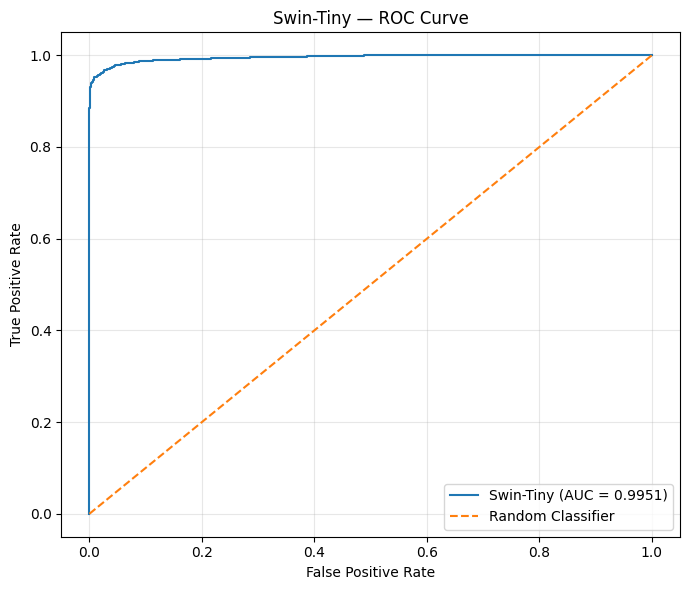

In [25]:
# ============================================================
# SWIN-TINY — ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_true_crack,
    crack_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Swin-Tiny (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Swin-Tiny — ROC Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 23. Classification report

In [25]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

report_text = classification_report(
    all_labels,
    all_predictions,
    target_names=test_ds.classes,
    digits=4,
    zero_division=0
)

print(report_text)

report_path = REPORT_DIR / f"{MODEL_KEY}_classification_report.txt"

with open(report_path, "w") as f:
    f.write(report_text)

print("Saved:", report_path)

              precision    recall  f1-score   support

       crack     0.9831    0.9570    0.9699      2000
    no_crack     0.9581    0.9835    0.9706      2000

    accuracy                         0.9702      4000
   macro avg     0.9706    0.9703    0.9702      4000
weighted avg     0.9706    0.9702    0.9702      4000

Saved: C:\Users\Students\Desktop\Crack classification(Indhu)\Output\reports\swin_tiny_scratch_classification_report.txt


## 24. Confusion matrix

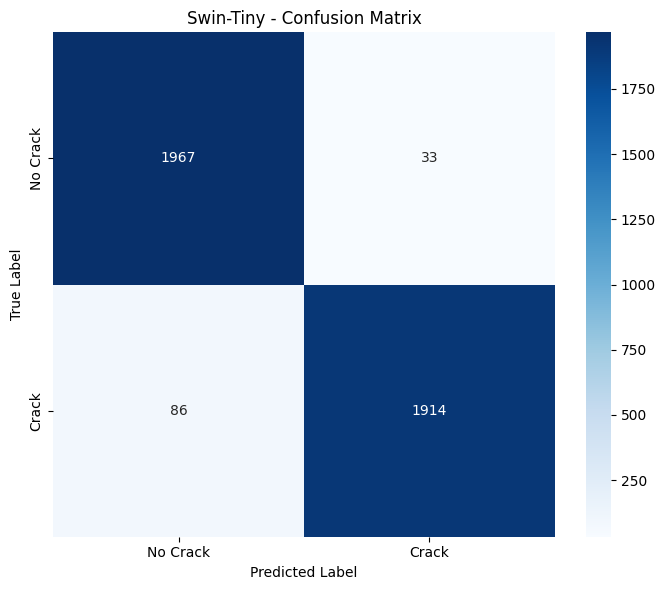

In [29]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

# Your Swin-Tiny class mapping is:
# crack = 0
# no_crack = 1
#
# Reorder to: No Crack, Crack
class_order = [1, 0]
cm = cm[np.ix_(class_order, class_order)]

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Crack", "Crack"],
    yticklabels=["No Crack", "Crack"],
    cmap="Blues",
    cbar=True
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Swin-Tiny - Confusion Matrix")

plt.tight_layout()
plt.show()

## 25. Save final metrics

This creates a CSV file that can be used later when comparing Swin-Tiny with the other classification models.

In [27]:
# ============================================================
# SAVE FINAL METRICS
# ============================================================

final_metrics = pd.DataFrame([{
    "model": "Swin-Tiny",
    "pretrained": False,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history["train_loss"]),
    "best_validation_accuracy": best_val_acc,
    "test_accuracy": test_accuracy,
    "weighted_precision": precision,
    "weighted_recall": recall,
    "weighted_f1": f1,
    "training_time_minutes": training_time / 60
}])

metrics_path = REPORT_DIR / f"{MODEL_KEY}_final_metrics.csv"

final_metrics.to_csv(
    metrics_path,
    index=False
)

display(final_metrics)

print("Saved:", metrics_path)

,model,pretrained,epochs_requested,epochs_completed,best_validation_accuracy,test_accuracy,weighted_precision,weighted_recall,weighted_f1,training_time_minutes
0,Swin-Tiny,False,50,50,0.967,0.97025,0.97058,0.97025,0.970245,154.53531


Saved: C:\Users\Students\Desktop\Crack classification(Indhu)\Output\reports\swin_tiny_scratch_final_metrics.csv


## 26. Final output locations

All important files are saved under the `Output` folder.

In [28]:
# ============================================================
# OUTPUT SUMMARY
# ============================================================

print("BEST MODEL:")
print(best_path)
print()

print("TRAINING LOG:")
print(csv_log_path)
print()

print("HISTORY:")
print(history_path)
print()

print("PLOTS:")
print(loss_plot_path)
print(acc_plot_path)
print(lr_plot_path)
print()

print("REPORTS:")
print(report_path)
print(cm_path)
print(metrics_path)

BEST MODEL:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\checkpoints\swin_tiny_scratch_best.pt

TRAINING LOG:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\logs\swin_tiny_scratch_epoch_log.csv

HISTORY:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\logs\swin_tiny_scratch_history.json

PLOTS:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\plots\swin_tiny_scratch_loss_curve.png
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\plots\swin_tiny_scratch_accuracy_curve.png
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\plots\swin_tiny_scratch_learning_rate.png

REPORTS:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\reports\swin_tiny_scratch_classification_report.txt
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\reports\swin_tiny_scratch_confusion_matrix.png
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\reports\swin_tiny_scratch_final_metrics.csv


# Done ✅

This notebook trains **Swin-Tiny from scratch** — no pretrained ImageNet weights are loaded.

For your paper, keep the actual values produced by this run for:
- Accuracy
- Weighted Precision
- Weighted Recall
- Weighted F1
- Training time
- Best validation accuracy

Do not copy expected values from another run; use the values printed by this notebook.